# Data Science Laboratory: Unsupervised Learning
Pablo Méndez

MsC. Computation Biomedical Engineering 2026-27

In [33]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.io import loadmat

# 1. Principal Component Analysis

In [34]:
features = ["age","bp","sg","al","su","rbc","pc","pcc","ba","bgr","bu","sc","sod","pot","hemo","pcv","wc","rc","htn","dm","cad","appet","pe","ane","class"]

In [35]:
df_kidney = pd.read_csv("../data/chronic_kidney_disease_ad.csv", names=features)

df_kidney.shape

(400, 25)

In [36]:
df_kidney.head()

,age,bp,sg,al,su,rbc,pc,pcc,ba,bgr,...,pcv,wc,rc,htn,dm,cad,appet,pe,ane,class
0,48.0,80.0,1.020,1.0,0.0,NaN,0.0,0.0,0.0,121.0,...,44.0,7800.0,5.2,1.0,1.0,0.0,0.0,0.0,0.0,1
1,7.0,50.0,1.020,4.0,0.0,NaN,0.0,0.0,0.0,NaN,...,38.0,6000.0,NaN,0.0,0.0,0.0,0.0,0.0,0.0,1
2,62.0,80.0,1.010,2.0,3.0,0.0,0.0,0.0,0.0,423.0,...,31.0,7500.0,NaN,0.0,1.0,0.0,1.0,0.0,1.0,1
3,48.0,70.0,1.005,4.0,0.0,0.0,1.0,1.0,0.0,117.0,...,32.0,6700.0,3.9,1.0,0.0,0.0,1.0,1.0,1.0,1
4,51.0,80.0,1.010,2.0,0.0,0.0,0.0,0.0,0.0,106.0,...,35.0,7300.0,4.6,0.0,0.0,0.0,0.0,0.0,0.0,1


In [37]:
df_kidney.info()

<class 'pandas.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 25 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   age     391 non-null    float64
 1   bp      388 non-null    float64
 2   sg      353 non-null    float64
 3   al      354 non-null    float64
 4   su      351 non-null    float64
 5   rbc     248 non-null    float64
 6   pc      335 non-null    float64
 7   pcc     396 non-null    float64
 8   ba      396 non-null    float64
 9   bgr     356 non-null    float64
 10  bu      381 non-null    float64
 11  sc      383 non-null    float64
 12  sod     313 non-null    float64
 13  pot     312 non-null    float64
 14  hemo    348 non-null    float64
 15  pcv     329 non-null    float64
 16  wc      294 non-null    float64
 17  rc      269 non-null    float64
 18  htn     398 non-null    float64
 19  dm      398 non-null    float64
 20  cad     398 non-null    float64
 21  appet   399 non-null    float64
 22  pe      399 n

## 1.1. Application to clinical data

### 1.1.1. Pre-processing of the data

**Why is this data a good candidate for dimensionality reduction?**

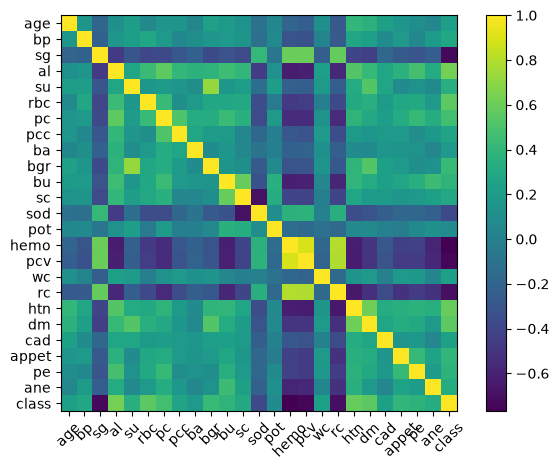

In [38]:
corr = df_kidney.corr()

plt.imshow(corr)
plt.colorbar()
plt.xticks(range(len(corr.columns)), corr.columns, rotation=45)
plt.yticks(range(len(corr.columns)), corr.columns)
plt.tight_layout()
plt.show()

In [39]:
means = df_kidney.mean()
df_kidney = df_kidney.fillna(means)

In [40]:
X = df_kidney.drop(columns="class")
y = df_kidney["class"]

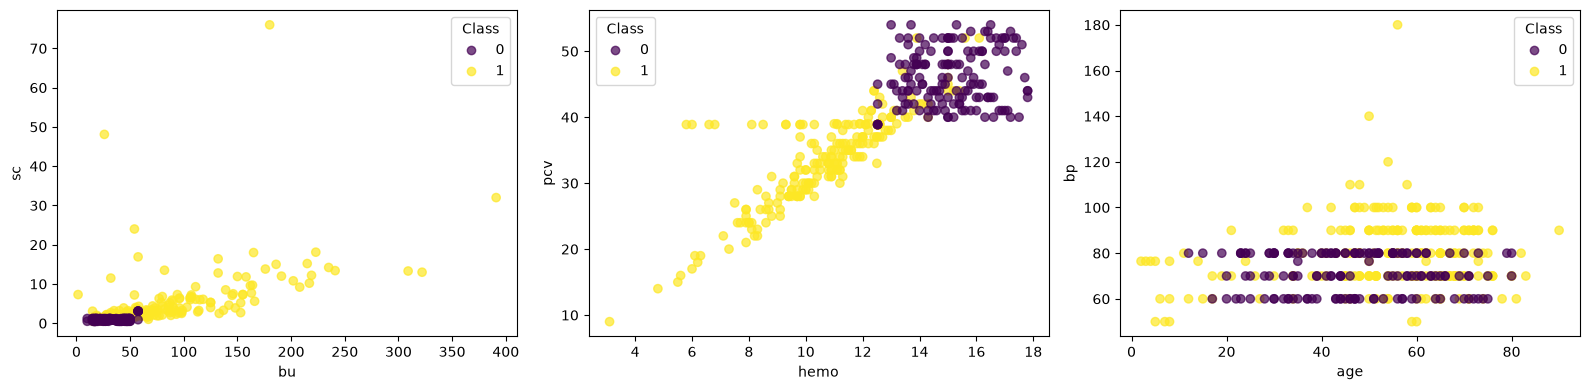

In [41]:
pairs = [("bu", "sc"), ("hemo", "pcv"), ("age", "bp")]

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, (a, b) in zip(axes, pairs):
	scatter = ax.scatter(X[a], X[b], c=y, alpha=0.7)
	ax.set_xlabel(a)
	ax.set_ylabel(b)
	ax.legend(*scatter.legend_elements(), title="Class")

plt.tight_layout()
plt.show()

## 1.2. Implementing PCA

**Standardize the variables to have zero mean and unit variance. Why the latter is important?**

In [42]:
means = X.mean(axis=0)
std = X.std(axis=0)

In [43]:
X_stand = (X-means)/std

In [44]:
X_stand.mean(), X_stand.std()

(age      5.062617e-16
 bp       7.460699e-16
 sg       2.273737e-15
 al       0.000000e+00
 su       0.000000e+00
 rbc      1.421085e-16
 pc      -1.421085e-16
 pcc     -1.776357e-17
 ba       3.552714e-17
 bgr     -1.421085e-16
 bu       1.243450e-16
 sc       0.000000e+00
 sod      0.000000e+00
 pot     -5.329071e-17
 hemo     0.000000e+00
 pcv      1.421085e-16
 wc       1.421085e-16
 rc      -2.842171e-16
 htn     -7.105427e-17
 dm       0.000000e+00
 cad     -3.552714e-17
 appet    0.000000e+00
 pe      -7.105427e-17
 ane      3.552714e-17
 dtype: float64,
 age      1.0
 bp       1.0
 sg       1.0
 al       1.0
 su       1.0
 rbc      1.0
 pc       1.0
 pcc      1.0
 ba       1.0
 bgr      1.0
 bu       1.0
 sc       1.0
 sod      1.0
 pot      1.0
 hemo     1.0
 pcv      1.0
 wc       1.0
 rc       1.0
 htn      1.0
 dm       1.0
 cad      1.0
 appet    1.0
 pe       1.0
 ane      1.0
 dtype: float64)

**Implement PCA to compute the principal components. Do not use the already existing Matlab function pca (or any other already implemented PCA function).**

In [45]:
def pca_manual(X, n_components=None):
	
	# 1. Center the features
	mean = X.mean(axis=0)
	centered = X - mean
	N = X.shape[0]

	# 2. Compute the covariance matrix
	covariance = centered.T @ centered / (N - 1)

	# 3. Compute eigenvalues and eigenvectors
	eigenvalues, eigenvectors = np.linalg.eigh(covariance)

	# 4. Sort by explained variance in descending order
	order = np.argsort(eigenvalues)[::-1]
	eigenvalues = eigenvalues[order]
	eigenvectors = eigenvectors[:, order]

	total_variance = eigenvalues.sum()

	# Each column represents a principal direction
	components = eigenvectors[:, :n_components]

	# 5. Project the observations onto the principal directions
	scores = centered @ components

	explained_ratio = eigenvalues[:n_components] / total_variance

	return scores, components, explained_ratio

In [46]:
scores, components, explained_ratio = pca_manual(X_stand)

scores.columns = [f"PC{i + 1}" for i in range(scores.shape[1])]

print("Explained variance ratio:", explained_ratio)
print("Cumulative explained variance:", np.cumsum(explained_ratio))

Explained variance ratio: [0.3007389  0.07704768 0.06724813 0.05323795 0.05063648 0.04498581
 0.0420948  0.04171764 0.03692619 0.03322702 0.03297044 0.0277886
 0.02656466 0.02505756 0.0213069  0.01792799 0.01789359 0.01572253
 0.01484655 0.01344365 0.01200071 0.01172135 0.00919392 0.00570095]
Cumulative explained variance: [0.3007389  0.37778658 0.44503471 0.49827266 0.54890914 0.59389495
 0.63598974 0.67770739 0.71463358 0.7478606  0.78083104 0.80861963
 0.8351843  0.86024186 0.88154876 0.89947676 0.91737034 0.93309287
 0.94793942 0.96138307 0.97338377 0.98510512 0.99429905 1.        ]


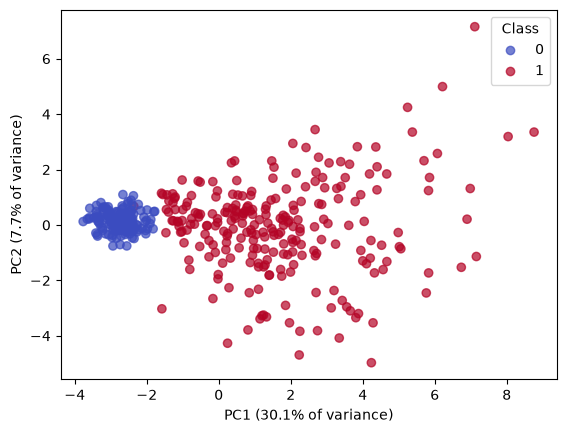

In [47]:
scatter = plt.scatter(
	scores.iloc[:, 0],
	scores.iloc[:, 1],
	c=y,
	cmap="coolwarm",
	alpha=0.7,
)

plt.xlabel(f"PC1 ({explained_ratio[0]:.1%} of variance)")
plt.ylabel(f"PC2 ({explained_ratio[1]:.1%} of variance)")
plt.legend(*scatter.legend_elements(), title="Class")
plt.show()

## 1.3. Application to face image data

In [48]:
data_faces = loadmat("../data/faces.mat")

X_faces = data_faces["X"]

In [51]:
def show_image(pixels, ax):
    image = np.asarray(pixels).reshape(32, 32, order="F")
    ax.imshow(image, cmap="gray")
    ax.axis("off")

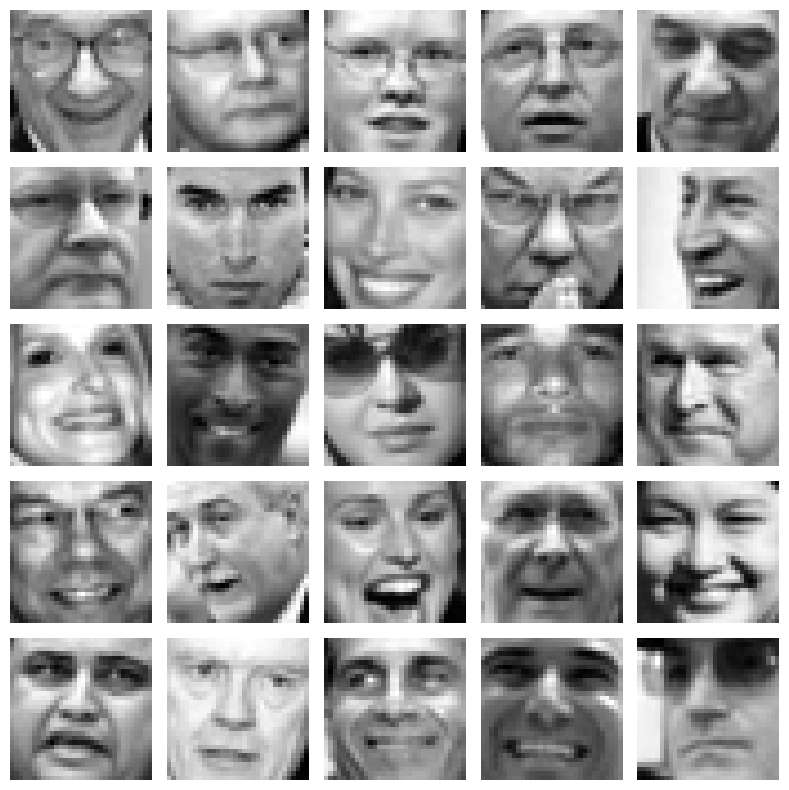

In [52]:
fig, axes = plt.subplots(5, 5, figsize=(8, 8))

images = np.asarray(X_faces)

for i, ax in enumerate(axes.flat):
    show_image(images[i], ax)

plt.tight_layout()
plt.show()